<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/red_neuronal_tensorflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tu primera red neuronal con TensorFlow
**Laboratorio de Códigos** · clasificación de dígitos escritos a mano (MNIST), paso a paso.

En Colab: *Entorno de ejecución → Ejecutar todas*. Funciona en CPU; con GPU, el entrenamiento tarda segundos.

## 1 · Datos
MNIST: 70 000 dígitos de 28×28 píxeles ya etiquetados (60 000 para entrenar y 10 000 para probar).

In [2]:
import tensorflow as tf
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print(x_train.shape, x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (10000, 28, 28)


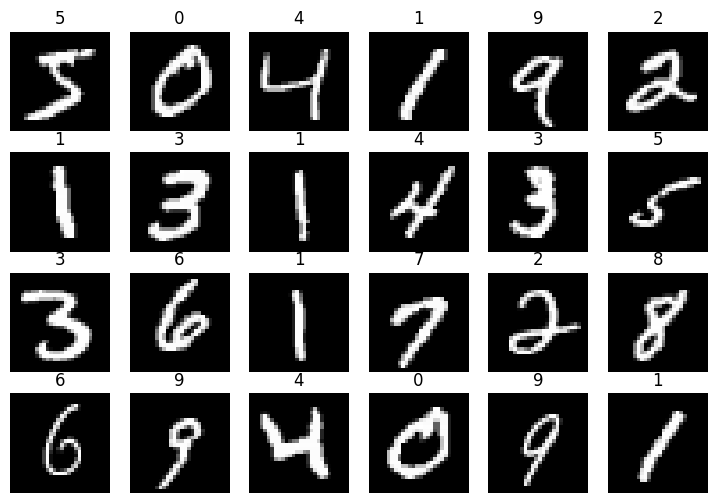

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(4, 6, figsize=(9, 6))
for i, a in enumerate(ax.flat):
    a.imshow(x_train[i], cmap='gray'); a.set_title(y_train[i]); a.axis('off')
plt.show()

## 2 · Normaliza
Cada imagen es una tabla de números entre 0 (negro) y 255 (blanco). Dividir entre 255 los deja entre 0 y 1, y así la red aprende más rápido.

In [4]:
print(x_train[0][12:19, 12:19])  # un trozo
x_train, x_test = x_train / 255.0, x_test / 255.0

[[190 253  70   0   0   0   0]
 [ 35 241 225 160 108   1   0]
 [  0  81 240 253 253 119  25]
 [  0   0  45 186 253 253 150]
 [  0   0   0  16  93 252 253]
 [  0   0   0   0   0 249 253]
 [  0   0  46 130 183 253 253]]


## 3 · Arquitectura
`Flatten` convierte 28×28 en 784 números, `Dense(128)` aprende rasgos, `Dropout` apaga el 20 % al entrenar para evitar memorizar y `Dense(10)` da una probabilidad por dígito.

In [5]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4 · Compila

In [6]:
model.compile(optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

# antes de entrenar: pesos al azar
print("acierto sin entrenar:", model.evaluate(x_test, y_test, verbose=0)[1])

acierto sin entrenar: 0.09210000187158585


## 5 · Entrena

In [7]:
hist = model.fit(x_train, y_train, epochs=5,
                 validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9097 - loss: 0.3119 - val_accuracy: 0.9657 - val_loss: 0.1216
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9544 - loss: 0.1544 - val_accuracy: 0.9735 - val_loss: 0.0918
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9655 - loss: 0.1138 - val_accuracy: 0.9758 - val_loss: 0.0794
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9711 - loss: 0.0940 - val_accuracy: 0.9785 - val_loss: 0.0752
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9749 - loss: 0.0805 - val_accuracy: 0.9772 - val_loss: 0.0780


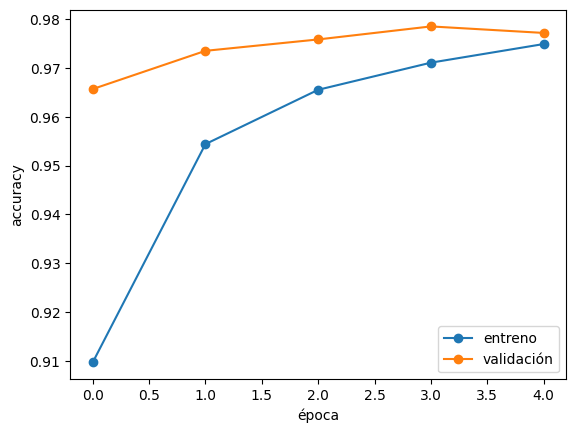

In [14]:
import matplotlib.pyplot as plt

plt.plot(hist.history['accuracy'], 'o-', label='entreno')
plt.plot(hist.history['val_accuracy'], 'o-', label='validación')
plt.xlabel('época'); plt.ylabel('accuracy'); plt.legend(); plt.show()

### ¿Qué aprendió?
Cada neurona de la capa `Dense(128)` tiene 784 pesos: verlos como una imagen de 28×28 muestra el trazo que busca.

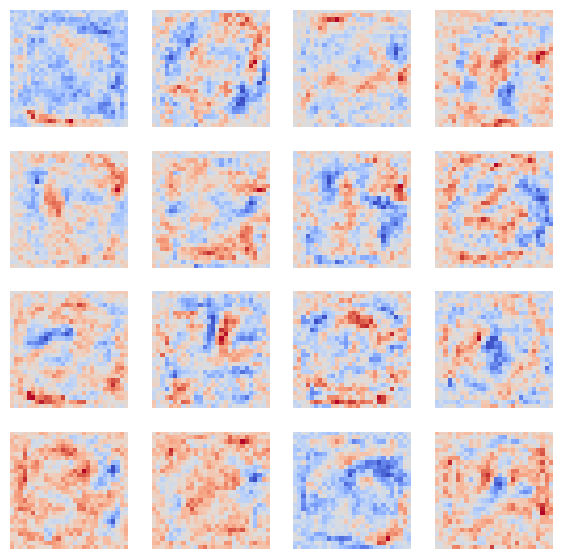

In [8]:
W = model.layers[1].get_weights()[0]  # (784, 128)
fig, ax = plt.subplots(4, 4, figsize=(7, 7))
for n, a in enumerate(ax.flat):
    a.imshow(W[:, n].reshape(28, 28), cmap='coolwarm'); a.axis('off')
plt.show()

## 6 · Evalúa con 10 000 imágenes que nunca vio

In [9]:
loss, acc = model.evaluate(x_test, y_test)
print(f"acierto: {acc:.2%}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9735 - loss: 0.0820
acierto: 97.35%


## 7 · Predice

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


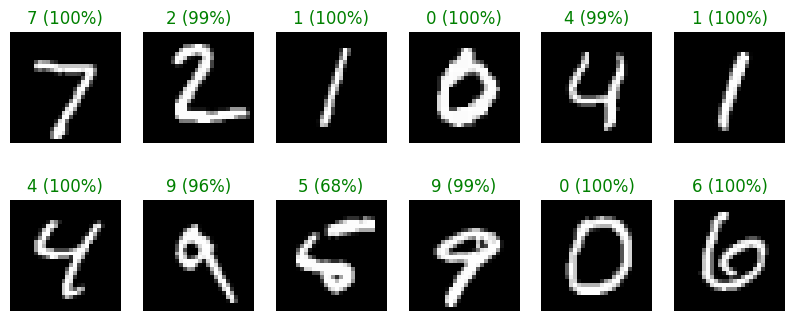

In [10]:
probs = model.predict(x_test[:12])
pred  = probs.argmax(axis=1)  # la clase más probable
fig, ax = plt.subplots(2, 6, figsize=(10, 4))
for i, a in enumerate(ax.flat):
    ok = pred[i] == y_test[i]
    a.imshow(x_test[i], cmap='gray'); a.axis('off')
    a.set_title(f"{pred[i]} ({probs[i].max():.0%})", color='green' if ok else 'red')
plt.show()

### ¿Dónde se equivoca?

265 errores de 10000


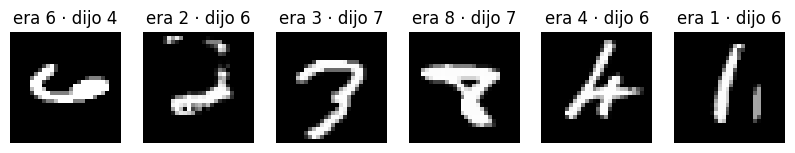

In [11]:
import numpy as np
P = model.predict(x_test, verbose=0); p = P.argmax(1)
err = np.where(p != y_test)[0]
print(len(err), "errores de", len(y_test))
err = err[np.argsort(-P[err].max(1))][:6]
fig, ax = plt.subplots(1, 6, figsize=(10, 2.4))
for a, i in zip(ax, err):
    a.imshow(x_test[i], cmap='gray'); a.axis('off'); a.set_title(f"era {y_test[i]} · dijo {p[i]}")
plt.show()

## Resultado final: con tu letra
Escribe un número con marcador sobre papel blanco, hazle una foto y súbela. `preparar()` la deja como MNIST: fondo negro, el dígito recortado a 20×20 y centrado por su centro de masa en 28×28.

In [12]:
from PIL import Image, ImageOps
from scipy import ndimage

def preparar(ruta):
    im = ImageOps.grayscale(Image.open(ruta))
    a = np.asarray(im, float)
    if a.mean() > 127: a = 255 - a          # papel blanco -> fondo negro
    a[a < 60] = 0
    ys, xs = np.nonzero(a)
    a = a[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    s = 20 / max(a.shape)
    a = np.asarray(Image.fromarray(a.astype(np.uint8)).resize((max(1, round(a.shape[1] * s)), max(1, round(a.shape[0] * s))), Image.LANCZOS), float)
    x = np.zeros((28, 28)); h, w = a.shape
    x[(28 - h) // 2:(28 - h) // 2 + h, (28 - w) // 2:(28 - w) // 2 + w] = a
    cy, cx = ndimage.center_of_mass(x)
    x = ndimage.shift(x, (14 - cy, 14 - cx))
    return np.clip(x / 255.0, 0, 1)

Saving images (1).jpeg to images (1).jpeg


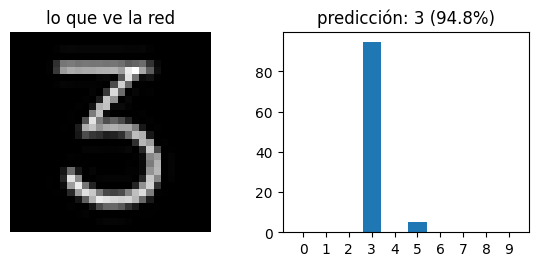

In [13]:
from google.colab import files
for ruta in files.upload():
    x = preparar(ruta)
    p = model.predict(x[None], verbose=0)[0]
    plt.figure(figsize=(7, 2.6))
    plt.subplot(1, 2, 1); plt.imshow(x, cmap='gray'); plt.axis('off'); plt.title('lo que ve la red')
    plt.subplot(1, 2, 2); plt.bar(range(10), p * 100); plt.xticks(range(10)); plt.title(f"predicción: {p.argmax()} ({p.max():.1%})")
    plt.show()

**Reto:** cambia `Dense(128)` por `Dense(256)` o entrena 10 épocas y comenta tu porcentaje.